# Why do patients miss medical appointments?
**110,521 appointments · 62,298 patients · public clinics in Vitória, Brazil · Apr–Jun 2016**

About 1 in 5 appointments in this dataset ends in a no-show. Each one is a wasted clinician slot and a patient who didn't get care. This notebook asks three questions:

1. **Who misses appointments?** (exploratory analysis + SQL)
2. **Do SMS reminders work?** (a confounding trap, then a controlled estimate)
3. **Can we predict no-shows a day ahead,** well enough to target reminder calls?

The pipeline lives in `src/` and can be re-run with `python run_all.py`; this notebook walks through the results.

In [1]:
import sys, json, sqlite3
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))

import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from IPython.display import Image, display

ROOT = Path.cwd().parent
FIG = ROOT / "reports" / "figures"
df = pd.read_csv(ROOT / "data/processed/appointments_clean.csv", parse_dates=["scheduled_at", "appointment_date"])
con = sqlite3.connect(ROOT / "data/processed/appointments.db")
sql = lambda q: pd.read_sql_query(q, con)
pd.set_option("display.precision", 3)
df.shape

(110521, 29)

## 1. Data cleaning
The raw Kaggle file (`KaggleV2-May-2016.csv`) needed a few fixes, all in `src/clean.py`:

| Issue | Fix |
|---|---|
| Typo'd column names (`Hipertension`, `Handcap`, `No-show`) | renamed to snake_case; target → 0/1 `no_show` |
| 1 patient with age −1 | dropped |
| 5 appointments dated *before* they were booked | dropped |
| `PatientId` stored as float | converted to string ID |
| Timestamps as text; appointment day has no time | parsed; `lead_days` = appointment date − booking date |

**Engineered features:** lead time and buckets, same-day flag, weekday, hour booked, age group, chronic-condition count, and **patient history**: how many earlier appointments a patient had and how many they missed. History uses only appointments on *earlier dates*, so the outcome being predicted never leaks into its own features.

In [2]:
df[["age", "lead_days", "prior_appts", "prior_no_shows", "no_show"]].describe().T

,count,mean,std,min,25%,50%,75%,max
age,110521.0,37.089,23.110,0.0,18.0,37.0,55.0,115.0
lead_days,110521.0,10.184,15.255,0.0,0.0,4.0,15.0,179.0
prior_appts,110521.0,1.176,3.797,0.0,0.0,0.0,1.0,83.0
prior_no_shows,110521.0,0.184,0.612,0.0,0.0,0.0,0.0,15.0
no_show,110521.0,0.202,0.401,0.0,0.0,0.0,0.0,1.0


## 2. Who misses appointments?
### Overview (SQL)

In [3]:
sql("""
SELECT COUNT(*) AS appointments, COUNT(DISTINCT patient_id) AS patients,
       SUM(no_show) AS no_shows, ROUND(100.0*AVG(no_show),1) AS no_show_pct
FROM appointments""")

,appointments,patients,no_shows,no_show_pct
0,110521,62298,22314,20.2


### Lead time is the dominant factor
Same-day appointments (35% of all bookings) are almost never missed: **under 5%**. Once a patient waits more than a week, roughly **1 in 3** don't show.

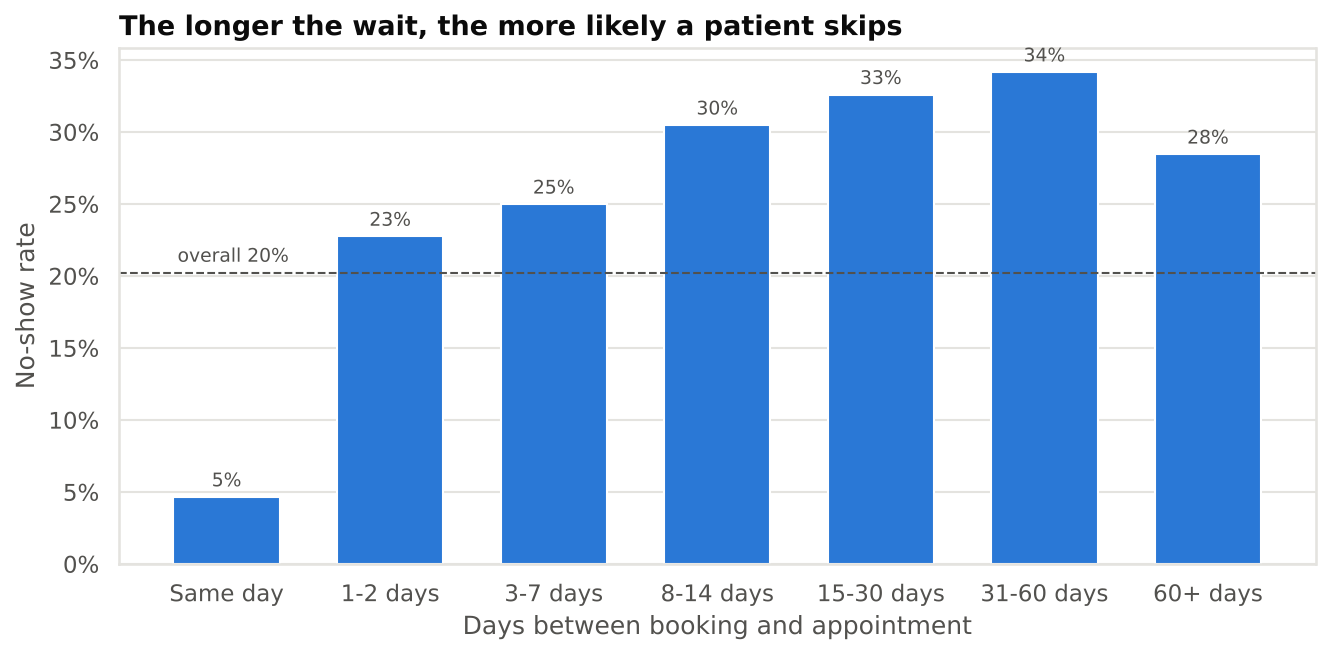

In [4]:
display(Image(FIG / "01_lead_time.png", width=760))

### Age: teenagers and young adults miss the most
No-show rates peak at 13–17 (27%) and fall steadily to ~15% for patients over 60.

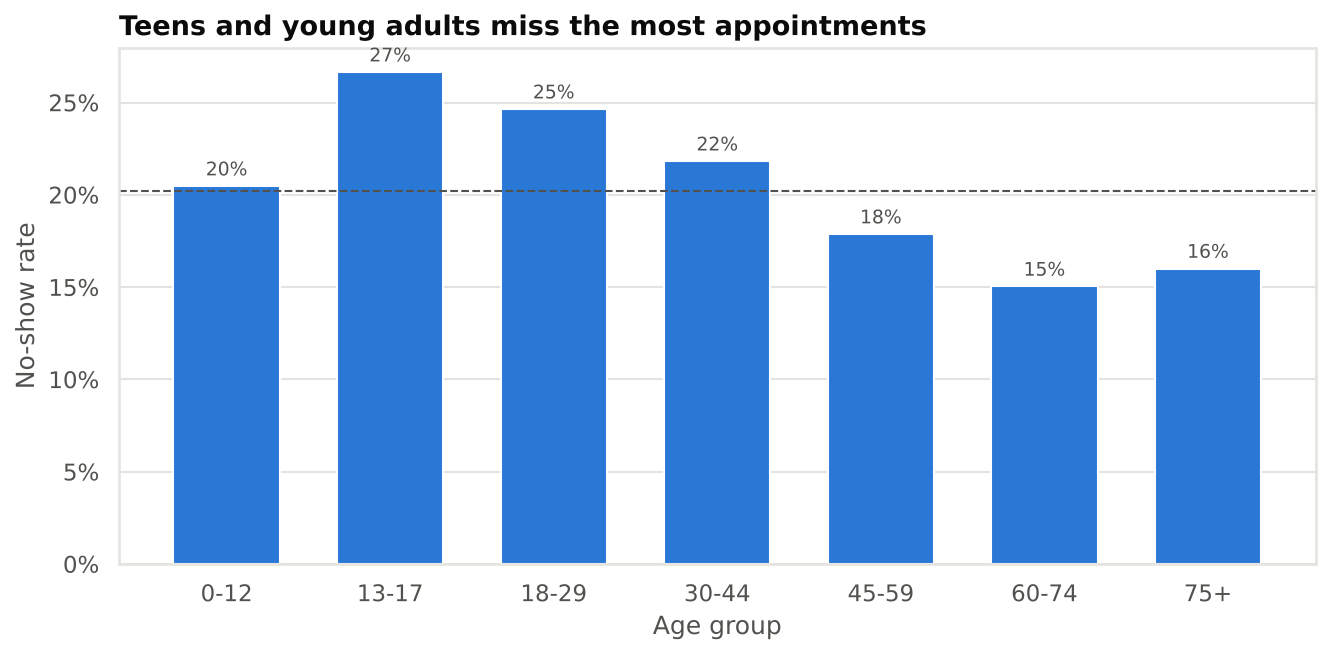

In [5]:
display(Image(FIG / "03_age.png", width=760))

### Health conditions and welfare
Patients with hypertension, diabetes or a handicap are slightly *more* reliable, likely because they're used to regular care. Patients enrolled in Bolsa Família (a welfare programme) miss more often (24% vs 20%), which points to access barriers like transport or work hours.

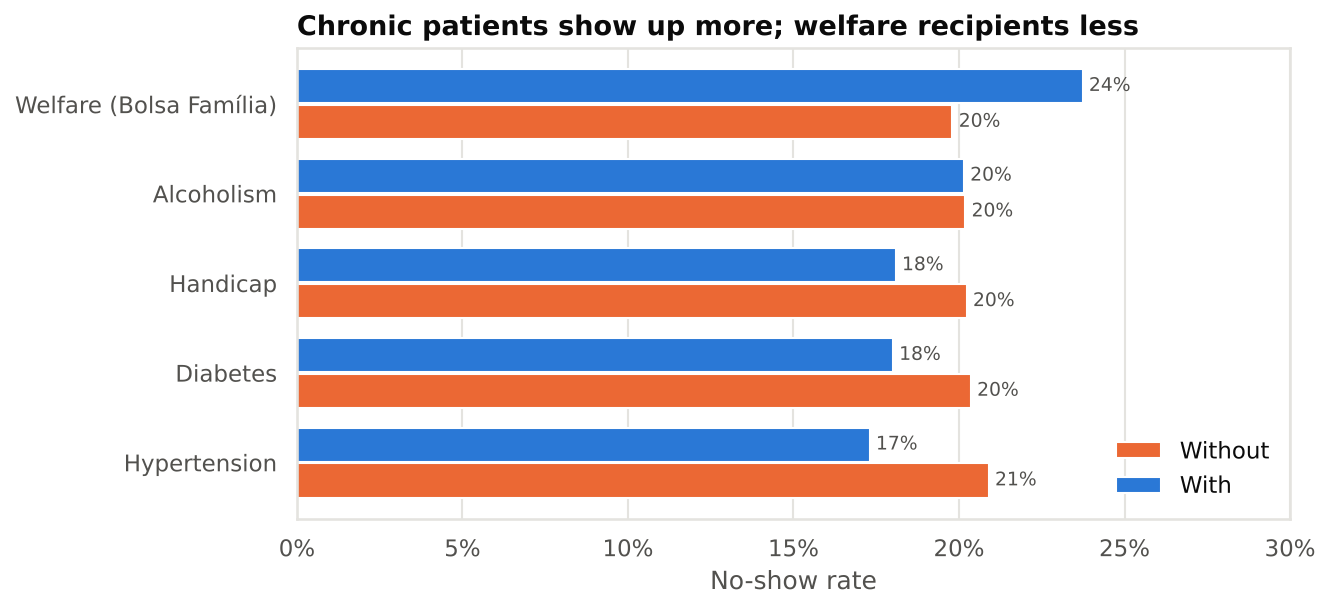

In [6]:
display(Image(FIG / "05_health_factors.png", width=760))

### Past behaviour predicts future behaviour
A patient who missed one earlier appointment has a 25% no-show rate; two or more misses pushes it to 32%. A patient who attended every earlier visit is no riskier than average.

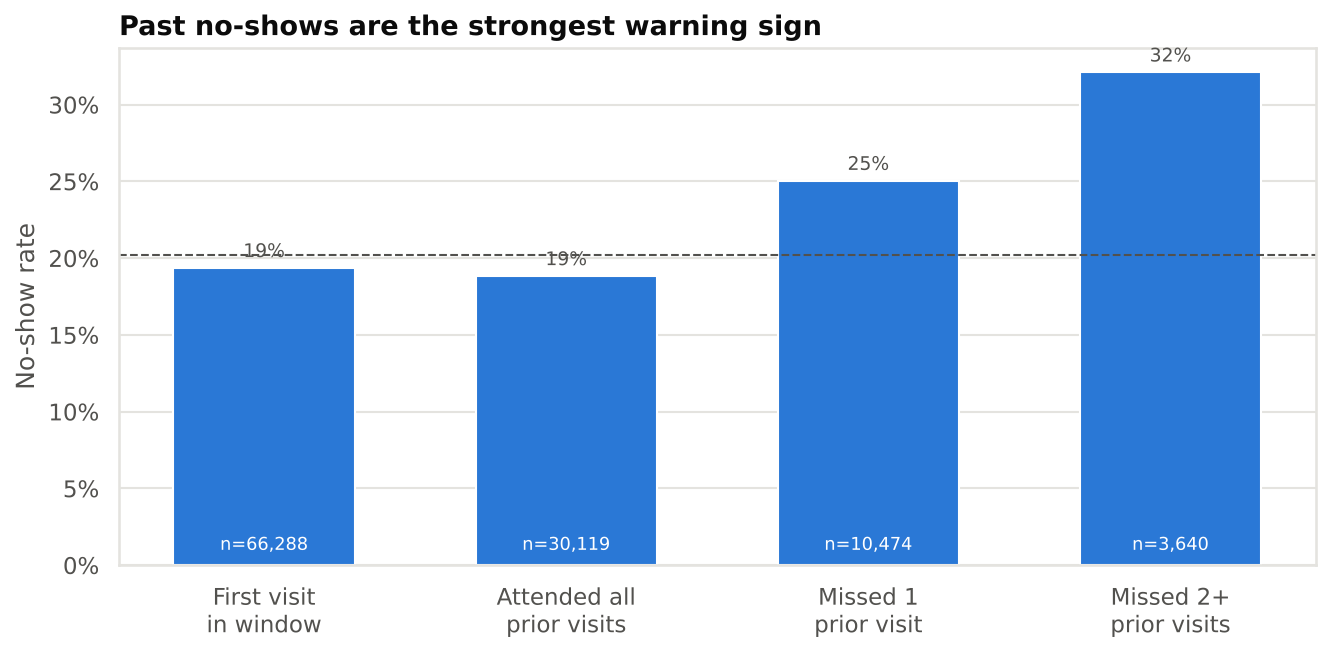

In [7]:
display(Image(FIG / "04_patient_history.png", width=760))

### Neighbourhood and weekday
Neighbourhood rates range from 16% to 29%, though most cluster near the average. Weekday barely matters (19–21%, Mon–Fri).

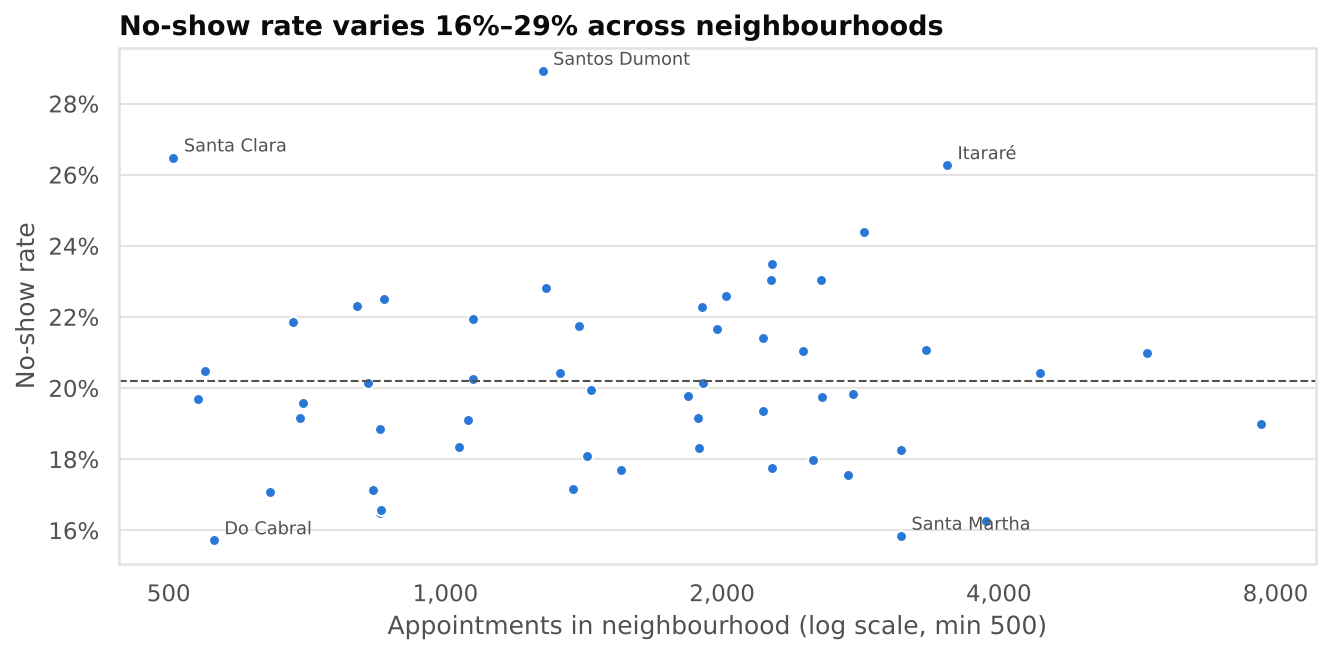

,appt_weekday,appts,no_show_pct
0,Mon,22713,20.6
1,Tue,25638,20.1
2,Wed,25866,19.7
3,Thu,17246,19.3
4,Fri,19019,21.2


In [8]:
display(Image(FIG / "06_neighbourhoods.png", width=760))
sql("""SELECT appt_weekday, COUNT(*) AS appts, ROUND(100.0*AVG(no_show),1) AS no_show_pct
FROM appointments WHERE appt_weekday != 'Sat' GROUP BY appt_weekday
ORDER BY CASE appt_weekday WHEN 'Mon' THEN 1 WHEN 'Tue' THEN 2 WHEN 'Wed' THEN 3 WHEN 'Thu' THEN 4 ELSE 5 END""")

## 3. Do SMS reminders work? A confounding trap
Compared naively, patients who got an SMS reminder look **more** likely to miss their appointment:

In [9]:
df.groupby("sms_received")["no_show"].agg(rate="mean", appointments="size")

,rate,appointments
sms_received,,
0,0.167,75039
1,0.276,35482


That would suggest reminders backfire. But SMS reminders were **only ever sent for appointments booked 3+ days ahead**. Same-day bookings, the group that almost always shows up, never received one:

In [10]:
df.groupby("lead_bucket")["sms_received"].mean().reindex(
    ["Same day", "1-2 days", "3-7 days", "8-14 days", "15-30 days", "31-60 days", "60+ days"]).rename("share_with_sms")

lead_bucket
Same day      0.000
1-2 days      0.000
3-7 days      0.570
8-14 days     0.582
15-30 days    0.606
31-60 days    0.611
60+ days      0.645
Name: share_with_sms, dtype: float64

This is **Simpson's paradox**: lead time drives both who gets an SMS and who skips. Comparing *within* each lead-time bucket flips the conclusion. SMS recipients miss **3–8 points less** in every bucket:

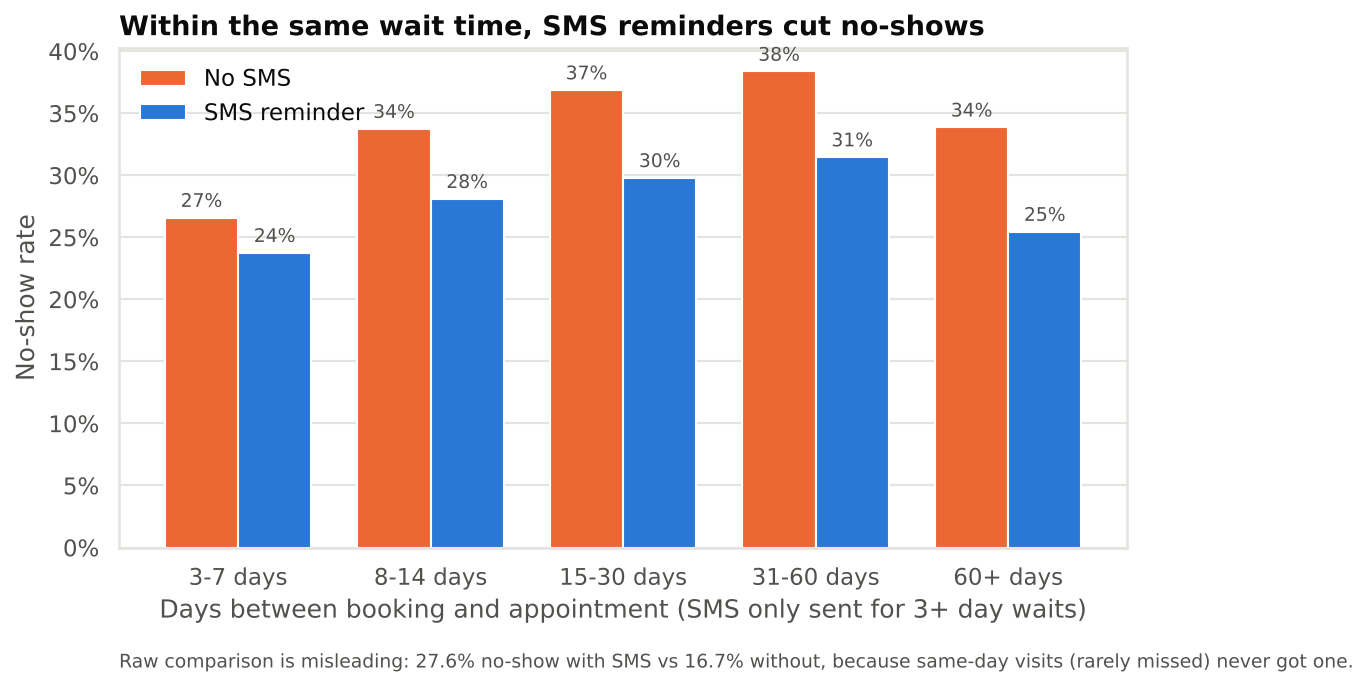

In [11]:
display(Image(FIG / "02_sms_by_lead_time.png", width=760))

To put a single number on it, fit a logistic regression on appointments that were eligible for an SMS (lead time ≥ 3 days). It controls for lead time, age, sex, welfare, chronic conditions and past no-shows:

In [12]:
elig = df[df["lead_days"] >= 3]
logit = smf.logit("no_show ~ sms_received + C(lead_bucket) + age + I(age**2) + welfare"
                  " + hypertension + diabetes + is_female + prior_no_shows", data=elig).fit(disp=0)
or_ = np.exp(logit.params["sms_received"]); lo, hi = np.exp(logit.conf_int().loc["sms_received"])
print(f"Odds ratio for SMS: {or_:.2f}  (95% CI {lo:.2f}–{hi:.2f}, p = {logit.pvalues['sms_received']:.1e})")
print(f"→ about {1-or_:.0%} lower odds of a no-show with a reminder, other factors held equal")

Odds ratio for SMS: 0.76  (95% CI 0.74–0.79, p = 9.8e-50)
→ about 24% lower odds of a no-show with a reminder, other factors held equal


**Caveat:** this is observational data. We don't know *how* the clinic chose who got an SMS beyond lead time, so this is strong evidence that reminders help, not proof. A randomised trial would settle it.

## 4. Predicting no-shows a day ahead
**Scenario:** each afternoon, staff rank tomorrow's appointments by risk and phone (or double-book) the riskiest ones.

**Setup** (`src/model.py`):
- **Time-based split:** train on appointments before 25 May 2016, test on 25 May – 8 June. A random split would let the model see the future.
- **Features:** only what's known the day before: demographics, conditions, lead time, booking hour, weekday, neighbourhood, SMS, past attendance.
- **Models:** logistic regression (interpretable baseline) and gradient boosting, compared with a one-rule baseline that ranks by lead time alone.

In [13]:
m = json.load(open(ROOT / "reports/metrics.json"))
print(f"train rows: {m['train_rows']:,} | test rows: {m['test_rows']:,} | test no-show rate: {m['test_no_show_rate']:.1%}")
pd.DataFrame(m["models"]).T.rename(columns={"roc_auc": "ROC-AUC", "pr_auc": "PR-AUC",
    "capture_top_20pct": "No-shows caught (top 20%)", "capture_top_30pct": "No-shows caught (top 30%)"})

train rows: 71,369 | test rows: 39,152 | test no-show rate: 18.6%


,ROC-AUC,PR-AUC,No-shows caught (top 20%),No-shows caught (top 30%)
Logistic regression,0.728,0.343,0.374,0.521
Gradient boosting,0.735,0.342,0.379,0.532
Baseline: lead time only,0.692,0.281,0.319,0.474


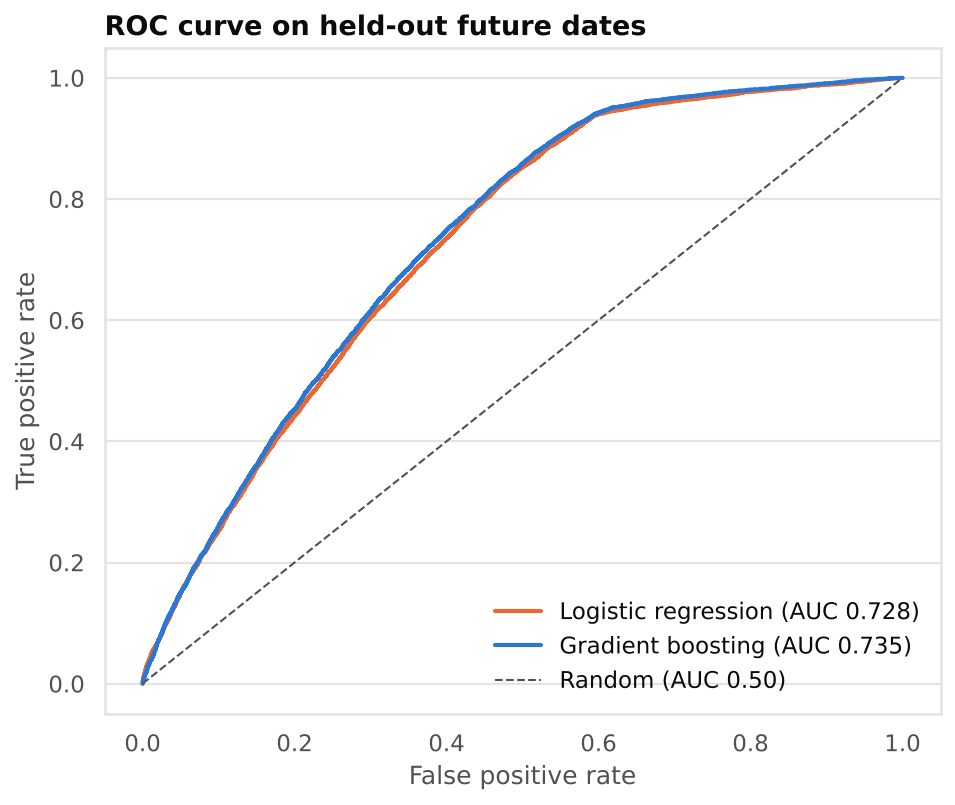

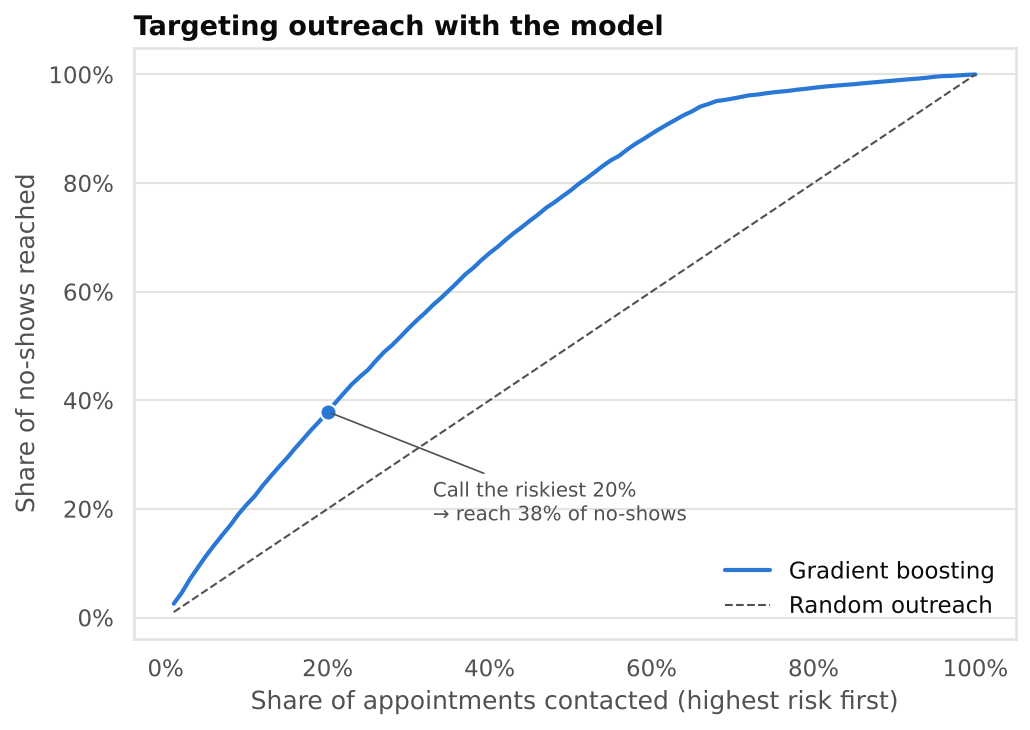

In [14]:
display(Image(FIG / "07_roc_curve.png", width=520))
display(Image(FIG / "09_capture_curve.png", width=560))

**Reading the results:**
- Both models beat the lead-time rule (ROC-AUC **0.735** vs 0.692). Gradient boosting edges out logistic regression only slightly, so a simple, explainable model would be a reasonable production choice.
- **Practical value:** calling the riskiest 20% of appointments reaches about **38% of all no-shows**, nearly double what random calls would reach (20%).
- **Honest limits:** ROC-AUC in the low 0.7s is typical for this dataset. The data has no visit reason, specialty, distance or weather, and those are probably what's needed to do much better.

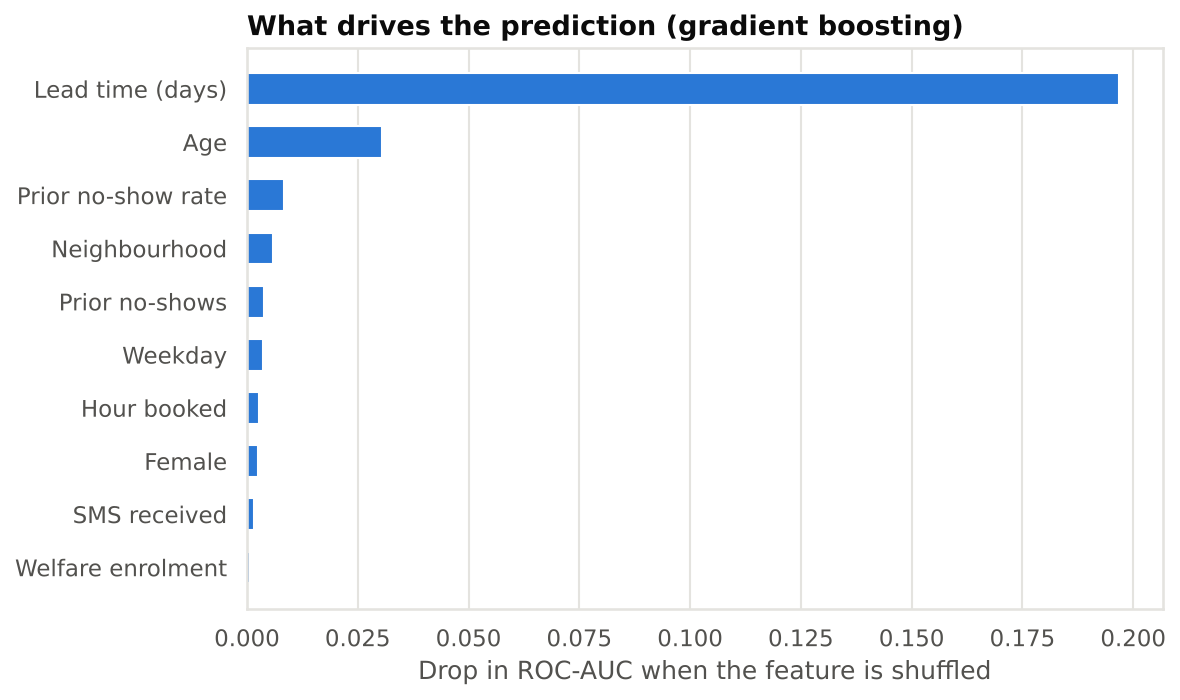

In [15]:
display(Image(FIG / "08_feature_importance.png", width=640))

Lead time dominates. Age and past no-show behaviour come next. SMS has little *predictive* power on its own because lead time already captures who receives one, even though section 3 shows that sending one does lower risk.

## 5. Recommendations
1. **Protect same-day and short-notice slots.** They're missed less than 5% of the time. Long booking queues are the single biggest risk factor.
2. **Extend SMS reminders to every appointment booked 1+ days out.** Reminders are linked to ~24% lower odds of a no-show, and today 1–2 day bookings get none.
3. **Use the risk score for targeted phone calls or overbooking** on the top 20–30% riskiest slots, especially for patients with earlier no-shows.
4. **Look into access barriers** for teens/young adults and welfare recipients, for example flexible hours or transport support.

## Limitations
- Six weeks of data from one city in 2016, so patterns may not transfer.
- "Prior no-shows" only counts history *inside* this window, so patients look newer than they really are.
- Observational: the SMS effect is an association that has been adjusted for confounders, not a randomised result.